
### Term Project: Milestone 3

## Cleaning/Formatting Website Data

Perform at least 5 data transformation and/or cleansing steps to your website data. The below examples are not required - they are just potential transformations you could do. If your data doesn't work for these scenarios, complete different transformations. You can do the same transformation multiple times if needed to clean your data. The goal is a clean dataset at the end of the milestone.

**Examples:**

- Replace Headers
- Format data into a more readable format
- Identify outliers and bad data
- Find duplicates
- Fix casing or inconsistent values
- Conduct Fuzzy Matching


### Website Data for Movie Project

For this portion I will be using the [Box Office Mojo](https://www.boxofficemojo.com/chart/top_lifetime_gross/) site, specifically focusing on the *Top Lifetime Grosses* Table on the ***All Time*** tab.

This table shows 200 records at a time and has 1,000 total records. I will want to be sure to pull all 1,000 entries from the table and will account for the pagination in the table while I scrape this data. I will also match up column names, where it makes sense, with my previous .csv file column names. The two I will ensure match, for later matching across my datasets, are *Movie_Title* and *Release_Year*, since I will use these two for correlation.

In [1]:
import requests
import pandas as pd
import io
import time

# base URL for the chart
base_url = "https://www.boxofficemojo.com/chart/top_lifetime_gross/"
headers = {"User-Agent": "Mozilla/5.0"}

all_movie_records = []

# offset starts at 0 and goes up by 200 (0, 200, 400, 600, 800)
# adjust range(0, 1000, 200) to get more or fewer pages
for offset in range(0, 1000, 200):
    # construct URL with offset
    url = f"{base_url}?offset={offset}"
    
    print(f"Fetching data from: {url}")
    response = requests.get(url, headers=headers)
    
    # use io.StringIO to avoid an OSError I received at one point
    page = pd.read_html(io.StringIO(response.text))[0]
    
    # standardize column names immediately to ensure successful concatenation of the data
    page.columns = ['Rank', 'Movie_Title', 'Lifetime_Gross', 'Release_Year']
    
    all_movie_records.append(page)
    
    # avoid hitting the server too fast - ETHICAL PAUSE
    time.sleep(1)

# combine all pages into one large DataFrame
web_movies = pd.concat(all_movie_records, ignore_index=True)

print("Initial Data Pull Completed\n")
print(f"Total rows scraped: {len(web_movies)}")

Fetching data from: https://www.boxofficemojo.com/chart/top_lifetime_gross/?offset=0
Fetching data from: https://www.boxofficemojo.com/chart/top_lifetime_gross/?offset=200
Fetching data from: https://www.boxofficemojo.com/chart/top_lifetime_gross/?offset=400
Fetching data from: https://www.boxofficemojo.com/chart/top_lifetime_gross/?offset=600
Fetching data from: https://www.boxofficemojo.com/chart/top_lifetime_gross/?offset=800
Initial Data Pull Completed

Total rows scraped: 1000


In [2]:
# verifying that the multi-page concatenation preserved our headers and checking for any null values introduced during the scrape.

print(f"Dataset Shape: {web_movies.shape}")
print("\nColumn Consistency Check:")
print(web_movies.columns.tolist())

# Check if any rows are missing data (common in multi-page scrapes)
print("\nMissing Values Per Column:")
print(web_movies.isnull().sum())

print("\n*** Step 1 Completed: Data Structure Validated ***")
web_movies.head()

Dataset Shape: (1000, 4)

Column Consistency Check:
['Rank', 'Movie_Title', 'Lifetime_Gross', 'Release_Year']

Missing Values Per Column:
Rank              0
Movie_Title       0
Lifetime_Gross    0
Release_Year      0
dtype: int64

*** Step 1 Completed: Data Structure Validated ***


,Rank,Movie_Title,Lifetime_Gross,Release_Year
0,1,Star Wars: Episode VII - The Force Awakens,"$936,662,225",2015
1,2,Avengers: Endgame,"$858,373,000",2019
2,3,Spider-Man: No Way Home,"$814,866,759",2021
3,4,Avatar,"$785,221,649",2009
4,5,Top Gun: Maverick,"$721,975,328",2022


In [3]:
# force conversion to numeric and handle any 'N/A' or symbols in the 1000+ records
web_movies['Lifetime_Gross'] = pd.to_numeric(
    web_movies['Lifetime_Gross'].astype(str).replace(r'[\$,]', '', regex=True), 
    errors='coerce'
).fillna(0).astype(int)

# clean up Release_Year as well - this is a just in case any of the dates are not just years
# ensure year is numeric; errors='coerce' turns bad data into NaN, which I will fill with 0
web_movies['Release_Year'] = pd.to_datetime(web_movies['Release_Year'], format='mixed', errors='coerce').dt.year.fillna(0).astype(int)

print("*** Step 2 Completed ***")
print("All records that should be numeric have been converted")
print("Release years validated - any bad data fixed")
print(web_movies.dtypes)

*** Step 2 Completed ***
All records that should be numeric have been converted
Release years validated - any bad data fixed
Rank              int64
Movie_Title         str
Lifetime_Gross    int64
Release_Year      int64
dtype: object


Trying to match numbers and strings does not work, since they will have different data types so any direct comparisons will fail. I want to ensure that columns will match across the different datasources, so I do not want any values that should be numeric to be strings, so I have converted them.

In [4]:
import re

# create the column I'll use later to join all the datasources
def normalize_title(title):
    title = str(title).lower()
    title = re.sub(r'[^a-z0-9\s]', '', title)
    return re.sub(r'\s+', ' ', title).strip()

web_movies['Simplified_Title'] = web_movies['Movie_Title'].apply(normalize_title)
print("*** Step #3 Complete ***")
print("Simplified_Title column generated for future merging.")

*** Step #3 Complete ***
Simplified_Title column generated for future merging.


The simplified column for the movie title name will be key for later correlation of my datasources. This way I can ensure that the movie title names are able to be joined without risk of random characters or differently capitalized titles preventing matching.

In [5]:
# Identify outliers- I'll look to identify top 10% performers
# calculate the 90th percentile only on movies with a recorded gross > 0
non_zero_gross = web_movies[web_movies['Lifetime_Gross'] > 0]['Lifetime_Gross']

if not non_zero_gross.empty:
    threshold = non_zero_gross.quantile(0.9)
    web_movies['Top_Tier_Performer'] = web_movies['Lifetime_Gross'] >= threshold
else:
    web_movies['Top_Tier_Performer'] = False

print("*** Step #4 Complete ***")
print(f"Top 10% threshold set at ${threshold:,.2f}")

*** Step #4 Complete ***
Top 10% threshold set at $322,907,123.10


### Outlier visualizations

I'm going to do a few plots since I think they are the best way to see outliers in the data. I will also do an IQR Calculation to identify my statistical outliers. 

*** Step 5 Completed ***
*** Outlier Visualization ***


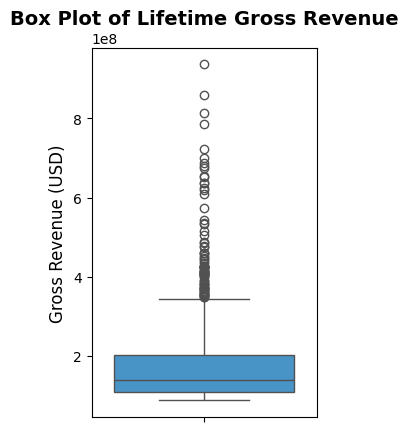

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Box Plot: shows the quartiles and the 'dots' (outliers) beyond the whiskers
plt.subplot(1, 2, 1)
sns.boxplot(y=web_movies['Lifetime_Gross'], color='#3498db')
plt.title('Box Plot of Lifetime Gross Revenue', fontsize=14, fontweight='bold')
plt.ylabel('Gross Revenue (USD)', fontsize=12)
print("*** Step 5 Completed ***")
print("*** Outlier Visualization ***")

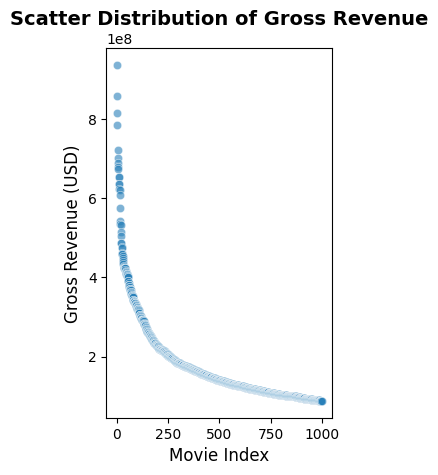

In [7]:
# Scatter Plot: shows the individual spread and how far the top movies sit from the pack
plt.subplot(1, 2, 2)
sns.scatterplot(x=web_movies.index, y=web_movies['Lifetime_Gross'], alpha=0.6, color='#2980b9')
plt.title('Scatter Distribution of Gross Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Movie Index', fontsize=12)
plt.ylabel('Gross Revenue (USD)', fontsize=12)

plt.show()

In [8]:
# calculating the IQR to identify exactly which movies are statistical outliers
q1 = web_movies['Lifetime_Gross'].quantile(0.25)
q3 = web_movies['Lifetime_Gross'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

outliers = web_movies[web_movies['Lifetime_Gross'] > upper_bound].sort_values(by='Lifetime_Gross', ascending=False)

print("*** Step 6 Complete ***\n")
print(f"Statistical Upper Bound (Anything above this is an outlier): ${upper_bound:,.2f}")
print(f"Total Outliers Identified: {len(outliers)}")
print("\nTop 5 Statistical Outliers:")
outliers.head(5)

*** Step 6 Complete ***

Statistical Upper Bound (Anything above this is an outlier): $345,776,807.75
Total Outliers Identified: 80

Top 5 Statistical Outliers:


,Rank,Movie_Title,Lifetime_Gross,Release_Year,Simplified_Title,Top_Tier_Performer
0,1,Star Wars: Episode VII - The Force Awakens,936662225,1970,star wars episode vii the force awakens,True
1,2,Avengers: Endgame,858373000,1970,avengers endgame,True
2,3,Spider-Man: No Way Home,814866759,1970,spiderman no way home,True
3,4,Avatar,785221649,1970,avatar,True
4,5,Top Gun: Maverick,721975328,1970,top gun maverick,True


In [9]:
# looking for the LOWEST earning movies
# filter for lifetime_gross > 0 to ignore any films that didn't have valid financial data
lowest_earners = web_movies[web_movies['Lifetime_Gross'] > 0].sort_values(by='Lifetime_Gross', ascending=True).head(5)

print("*** Step 7 Complete ***")
print("*** 5 Lowest Earning Movies (Excluding $0 entries) ***")
lowest_earners.head(5)

*** Step 7 Complete ***
*** 5 Lowest Earning Movies (Excluding $0 entries) ***


,Rank,Movie_Title,Lifetime_Gross,Release_Year,Simplified_Title,Top_Tier_Performer
999,1000,Along Came Polly,88097164,1970,along came polly,False
998,999,Starsky & Hutch,88237754,1970,starsky hutch,False
997,998,Waterworld,88246220,1970,waterworld,False
996,997,Back to the Future Part III,88277583,1970,back to the future part iii,False
995,996,Anyone But You,88319668,1970,anyone but you,False


In [10]:
web_movies.shape

(1000, 6)

In [11]:
# export dataset to CSV
web_movies.to_csv('box_office_mojo.csv', index=False)

# print final dataset (small portion)
print("*** Final Cleaned Milestone 3 Dataset ***\n")
web_movies.head()

*** Final Cleaned Milestone 3 Dataset ***



,Rank,Movie_Title,Lifetime_Gross,Release_Year,Simplified_Title,Top_Tier_Performer
0,1,Star Wars: Episode VII - The Force Awakens,936662225,1970,star wars episode vii the force awakens,True
1,2,Avengers: Endgame,858373000,1970,avengers endgame,True
2,3,Spider-Man: No Way Home,814866759,1970,spiderman no way home,True
3,4,Avatar,785221649,1970,avatar,True
4,5,Top Gun: Maverick,721975328,1970,top gun maverick,True


## Ethical Implications of Website Data Wrangling

**Data Sourcing and Credibility**

This data was pulled from the Box Office Mojo site, which is a highly credible subsidiary of IMDb and the industry standard for box office tracking. The data was acquired ethicallying by using only 5 HTTP requests to access a public table of data. I included a sleep timer so as to not overload the server with calls, and ensured that no private or paywalled information was accessed.

**Transformations and Assumptions**

Key transformations completed included converting currency strings to integers and normalizing titles into a Simplified Title that I will be able to use for joining all the different datasources later on. I assumed that any $0$ or *NaN* values in the release year were due to scraping artifacts and could be defaulted to 0 without compromising the primary financial analysis. 

With the right skew of this dataset, and 8% or so of this dataset being classified as outliers means if I continued this project past this class, and chose to do any machine learning on it, any linear regression models performed would be heavily biased toward these top performers. I have created the *Top_Tier_Performer* boolean flag as a mitigation strategy to allow me to ethically represent this data by acknowledging that these 80 movies belong to a different tier than the rest of the dataset. I would not want to delete these since they are the most successful examples for the movie industry.

**Outlier Analysis: Lifetime Gross Revenue**

This dataset is specifically on Top Lifetime Grosses, but I do expect to see some spread within these top earning movies. The distribution of the *Lifetime_Gross* data is significantly right-skewed, which is a characteristic of the 'blockbuster' economy in the film industry. By utilizing the Interquartile Range (IQR) method, I was able to calculate the statistical upper bound to be $345,776,807.75 (as of the date I pulled this data). This bound creates a clear distinction between a *high-performing* film and a *mega-blockbuster* film. With the IQR I was able to find that there are 80 movies that are identified as statistical outliers and would be considered the *Mega-Blockbuster* movie class with the top all time grossing movie being *Star Wars: Episode VII - The Force Awakens* at \$936.6M, which is nearly three times the amount of the statistical outlier threshold. 

**Legal and Mitigation**

While movie grosses are public data, the specific arrangement on Box Office Mojo is proprietary. Box Office Mojo is owned by IMDb, which is an Amazon company, and is protected by copyright. Additional detailed, specialized, and historical breakdowns are available if you have an IMDbPro subscription service. To respect legal guidelines of the copyrighted data, this analysis is limited to academic use only.

A risk created by the Simplified Title transformation is title collision, where a remake and an original film could be merged incorrectly. To mitigate this, I have preserved the original Movie Title and Release Year for secondary verification during the final correlation phase.